# Search for the Key (Grover's Search)

*Secure the Grid · Step 2, Part 5 · from UTC's problem set (Problem 1)*

Symmetric encryption such as AES protects data with one secret key. An attacker without it has to search all N possible keys: up to N tries on a classical computer. Grover's search finds one marked item among N in about √N quantum steps. Each step has to run the whole check on a quantum computer, and the steps can't be split across many machines the way classical guessing can. Here the marked item stands in for the right key, and the oracle stands in for "does this key decrypt the message?" Our oracle is built from the answer; a real attack's oracle is the AES circuit itself, testing a known plaintext and ciphertext, which is what makes each step so expensive.

**Your job:** fill in the two `TODO` functions (the oracle and the diffusion operator) and run the search on the simulator for N = 4 and N = 8. N = 16 and the IonQ simulator run are optional. Then answer the written question in the README (Step 2, Part 5): what Grover's search means for AES key length, and how fixing it compares with fixing RSA. Check what NIST's post-quantum FAQ says about AES-128 before you answer.

> **Before you run anything, pick the kernel.** When this notebook opens, a **Select Kernel** box appears with *Python 3 (ipykernel)* already selected. That's the wrong one: change it to **qBraid-SDK (v0.12.2)**, then click **Select**. Picked the wrong one, or closed the box? Click the kernel name at the top right of the notebook and choose **qBraid-SDK (v0.12.2)**. The first cell checks, and tells you if it's wrong.

In [1]:
# Use the qBraid-SDK (v0.12.2) kernel. This stops with a clear message if another one is picked.
import importlib.util
missing = [m for m in ("qbraid", "matplotlib") if importlib.util.find_spec(m) is None]
if missing:
    raise ImportError("Wrong kernel: this one has no " + " or ".join(missing) + ". Click the kernel name "
                      "at the top right of the notebook, pick qBraid-SDK (v0.12.2), then run this cell again.")

# Qiskit Aer is Qiskit's simulator. It runs right here in your Lab instance: instant, free and noise-free,
# with no job and no credits. The first run installs it (a few seconds), pinned to the version tested here.
try:
    import qiskit_aer  # noqa: F401
except ImportError:
    %pip install -q qiskit-aer==0.18.2

# Setup
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

sim = AerSimulator()

print("Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.")

Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.


In [14]:
# Problem parameters
N = 4                       # number of possible keys (try 4, then 8; 16 is optional)
n = int(np.log2(N))         # number of qubits
secret_key = 2              # the key to find (0..N-1); try changing it

# Optimal number of Grover iterations
iterations = int(np.floor((np.pi / 4) * np.sqrt(N)))
print(f"N={N}, qubits={n}, key={secret_key}, iterations={iterations}")


N=4, qubits=2, key=2, iterations=1


In [15]:
def oracle(qc, qubits, marked):
    bits = format(marked, f"0{len(qubits)}b")[::-1]   # the key's digits, one per qubit
    # 1) flip the 0-digits so the right key looks like all 1s
    for i, q in enumerate(qubits):
        if bits[i] == "0":
            qc.x(q)
    # 2) the "flip volume if all 1s" tool (built from h, mcx, h)
    qc.h(qubits[-1])
    qc.mcx(qubits[:-1], qubits[-1])
    qc.h(qubits[-1])
    # 3) flip those digits back
    for i, q in enumerate(qubits):
        if bits[i] == "0":
            qc.x(q)

In [16]:
def diffusion(qc, qubits):
    qc.h(qubits)
    qc.x(qubits)
    qc.h(qubits[-1])
    qc.mcx(qubits[:-1], qubits[-1])
    qc.h(qubits[-1])
    qc.x(qubits)
    qc.h(qubits)

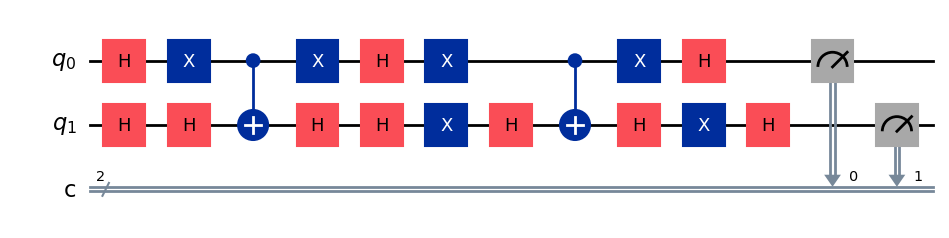

In [17]:
# Assemble the full Grover circuit (works once the TODOs are filled in)
def build_grover(n, marked, iterations):
    qc = QuantumCircuit(n, n)
    qubits = list(range(n))
    qc.h(qubits)                       # equal superposition
    for _ in range(iterations):
        oracle(qc, qubits, marked)
        diffusion(qc, qubits)
    qc.measure(qubits, qubits)
    return qc

qc = build_grover(n, secret_key, iterations)
qc.draw("mpl")


Most likely key (binary): 10 = key 2


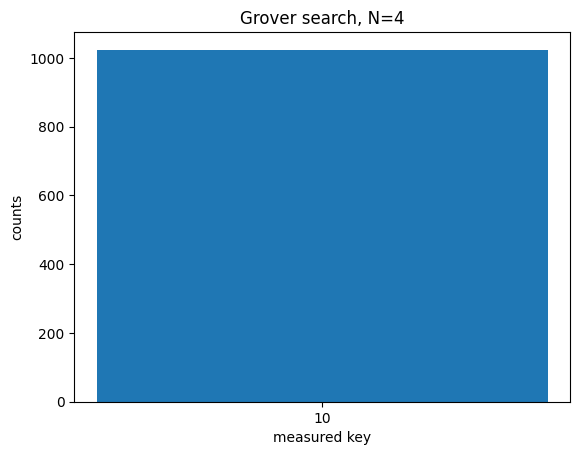

In [18]:
# Run on the simulator
tqc = transpile(qc, sim)
counts = sim.run(tqc, shots=1024).result().get_counts()

# The most frequent result should be the secret key
best = max(counts, key=counts.get)
print("Most likely key (binary):", best, "= key", int(best, 2))

plt.bar(counts.keys(), counts.values())
plt.title(f"Grover search, N={N}")
plt.xlabel("measured key"); plt.ylabel("counts"); plt.show()


### Optional: run it through qBraid

IonQ's simulator is free, and its `noise_model` option adds IonQ's gate noise, which sits mostly on two-qubit gates. Grover's circuit grows fast: N = 4 needs 2 two-qubit gates, N = 8 about 24 and N = 16 about 84. Does the peak change as N grows? Note by how much, and what that says about running Grover's search on today's hardware. Quantinuum's free H2 emulator models different hardware: try the same N on both and compare. A real-QPU run is optional and uses credits: ask a mentor first, use N = 4 or 8, and cap it at 200 shots.

In [ ]:
# --- Run on a quantum computer through qBraid ---
from qbraid.runtime import QbraidProvider
import warnings
warnings.filterwarnings("ignore", message="Circuit contains measurement gates")  # IonQ measures every qubit anyway

provider = QbraidProvider()   # in qBraid Lab this uses your account automatically

# 1) Practice for free: IonQ's simulator with an approximate noise model of IonQ Forte
# device = provider.get_device("ionq:ionq:sim:simulator")
# job = device.run(qc, shots=200, runtime_options={"noise_model": "forte-1"})

# 2) Your real hardware run (uses credits). Swap these in when you're ready:
# device = provider.get_device("ionq:ionq:qpu:forte-1")    # or "aws:ionq:qpu:forte-1" if this one shows as unavailable
# job = device.run(qc, shots=200)

# 3) Also free: Quantinuum's H2 emulator. It models a real trapped-ion computer's noise, readout
#    error included. Accept Quantinuum's terms once first (Devices > Quantinuum in your qBraid account).
#    It's an emulator: label its results that way, not as hardware.
device = provider.get_device("quantinuum:quantinuum:sim:h2-emulator")
job = device.run(qc, shots=200)

print("Job ID:", job.id)          # copy this into your write-up
hw_counts = job.result().data.get_counts()
print(hw_counts)

/home/jovyan/.qbraid/environments/qbraid_fwnp/pyenv/lib/python3.12/site-packages/qbraid_core/_compat.py:39: UserWarning: You are using qbraid-core version 0.3.0, however, version 0.6.53 is available. To avoid compatibility issues, consider upgrading.
  warnings.warn(


Job ID: quantinuum:quantinuum:sim:h2-emulator-0ad7-qjob-6af86c52c8f5265fb3f1b0ee


## What to have ready (Step 2, Part 5)
- The search running on the simulator for N = 4 and N = 8, with the histogram peaking on the secret key each time.
- Optional: N = 16, and the IonQ simulator and Quantinuum emulator results, with a note on how noise changed the peak.
- Your written answer in `WRITEUP.md`: what Grover's search means for symmetric key length (like AES), and how fixing it compares with fixing RSA.
- **For your deck:** one line on where symmetric keys fit in your migration plan.